# Rainbow: Combining Improvements in Deep Reinforcement Learning

**Paper:** Hessel, M., Modayil, J., van Hasselt, H., Schaul, T., Ostrovski, G., Dabney, W., Horgan, D., Piot, B., Azar, M., & Silver, D. (2018). *Rainbow: Combining Improvements in Deep Reinforcement Learning.* AAAI 2018. [arXiv:1710.02298](https://arxiv.org/abs/1710.02298)

The paper combines six extensions of DQN in one agent: Double Q-learning, prioritized replay, dueling networks, multi-step returns, distributional RL and noisy nets. This notebook implements a simplified version with three of them, **Double DQN**, **Dueling Networks** and **Prioritized Experience Replay**, and trains five agents on CartPole-v1 with the same seed and settings: vanilla DQN, each of the three extensions alone, and the three combined. A separate section adds 3-step returns to Double DQN.

The Summary at the end says what this run found.


## 1. Setup & Imports

In [1]:
import atexit
import os
import shutil
import subprocess
import sys

# Install gymnasium if not available
try:
    import gymnasium
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "gymnasium", "-q"],
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    import gymnasium as gym
else:
    import gymnasium as gym

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
from collections import deque
import random
import warnings
warnings.filterwarnings('ignore')

# Show figures as JPEG at a modest resolution to keep the saved notebook small
set_matplotlib_formats('jpeg')
plt.rcParams['figure.dpi'] = 80

# On Kaggle (detected from its environment), keep a copy of this notebook with its outputs when
# the kernel exits, so `kaggle kernels output` can download the executed version
if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    atexit.register(lambda: os.path.exists('__notebook__.ipynb')
                    and shutil.copy('__notebook__.ipynb', 'executed_solution.ipynb'))

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
# One CPU thread and deterministic kernels, so results do not depend on the machine's core count
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cpu


## 2. Hyperparameters

All agents share identical hyperparameters for fair comparison, except for the algorithm-specific differences (dueling architecture, prioritized sampling).

In [2]:
# Environment
ENV_NAME = "CartPole-v1"
STATE_DIM = 4
ACTION_DIM = 2

# Network
HIDDEN_DIM = 128
LR = 1e-3

# Reinforcement learning
GAMMA = 0.99
BUFFER_SIZE = 20_000
BATCH_SIZE = 64
TARGET_UPDATE_FREQ = 200  # steps

# Exploration (epsilon-greedy)
EPSILON_START = 1.0
EPSILON_END = 0.05
EPSILON_DECAY = 0.995

# Training
NUM_EPISODES = 250
MAX_STEPS = 500

# Prioritized Experience Replay
ALPHA = 0.6          # prioritization exponent
BETA_START = 0.4     # importance-sampling start
BETA_END = 1.0       # importance-sampling end
BETA_FRAC = 0.6      # fraction of training to anneal beta over
EPS_PRI = 1e-6       # small constant for non-zero priorities

# Multi-step (optional extension)
N_STEP = 3

print(f"Environment: {ENV_NAME}")
print(f"State dim: {STATE_DIM}, Action dim: {ACTION_DIM}")
print(f"Episodes: {NUM_EPISODES}, Max steps: {MAX_STEPS}")

Environment: CartPole-v1
State dim: 4, Action dim: 2
Episodes: 250, Max steps: 500


## 3. Environment Setup

In [3]:
env = gym.make(ENV_NAME)
print(f"Observation space: {env.observation_space}")
print(f"Action space: {env.action_space}")

# Quick test episode
obs, _ = env.reset(seed=SEED)
env.action_space.seed(SEED)
total = 0
for _ in range(50):
    action = env.action_space.sample()
    obs, reward, terminated, truncated, _ = env.step(action)
    total += reward
    if terminated or truncated:
        break
print(f"Random episode reward (50 steps max): {total}")
env.close()

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
Random episode reward (50 steps max): 30.0


## 4. Q-Network Architectures

### Standard Q-Network (for Vanilla DQN and Double DQN)

A simple MLP that maps state → Q-values for all actions.

In [4]:
class QNetwork(nn.Module):
    """Standard MLP Q-network: state -> Q(s, a) for all actions."""
    def __init__(self, state_dim, action_dim, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )

    def forward(self, x):
        return self.net(x)

# Test
net = QNetwork(STATE_DIM, ACTION_DIM).to(device)
test_input = torch.randn(4, STATE_DIM).to(device)
print(f"QNetwork output shape: {net(test_input).shape}")  # (4, 2)

QNetwork output shape: torch.Size([4, 2])


### Dueling Q-Network (for Dueling DQN and Rainbow)

Splits the network into a **value stream** V(s) and an **advantage stream** A(s,a), combining them as:

Q(s, a) = V(s) + A(s, a) - mean_a A(s, a)

This decouples the value of being in a state from the advantage of each action, improving learning when many actions are similar.

In [5]:
class DuelingQNetwork(nn.Module):
    """Dueling Q-network: shared trunk -> value stream + advantage stream."""
    def __init__(self, state_dim, action_dim, hidden_dim=128):
        super().__init__()
        # Shared feature trunk
        self.trunk = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )
        # Value stream: V(s) -> scalar
        self.value_stream = nn.Linear(hidden_dim, 1)
        # Advantage stream: A(s, a) -> one per action
        self.advantage_stream = nn.Linear(hidden_dim, action_dim)

    def forward(self, x):
        features = self.trunk(x)
        value = self.value_stream(features)                  # (batch, 1)
        advantage = self.advantage_stream(features)           # (batch, action_dim)
        # Combine: Q(s,a) = V(s) + A(s,a) - mean_a[A(s,a)]
        q = value + advantage - advantage.mean(dim=1, keepdim=True)
        return q

# Test
duel_net = DuelingQNetwork(STATE_DIM, ACTION_DIM).to(device)
print(f"DuelingQNetwork output shape: {duel_net(test_input).shape}")  # (4, 2)

DuelingQNetwork output shape: torch.Size([4, 2])


## 5. Replay Buffers

### Standard (Uniform) Replay Buffer

Stores transitions and samples random minibatches uniformly. Used by Vanilla DQN, Double DQN, and Dueling DQN.

In [6]:
class ReplayBuffer:
    """Uniform random sampling replay buffer."""
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (
            torch.FloatTensor(np.array(states)).to(device),
            torch.LongTensor(actions).to(device),
            torch.FloatTensor(rewards).to(device),
            torch.FloatTensor(np.array(next_states)).to(device),
            torch.FloatTensor(dones).to(device)
        )

    def __len__(self):
        return len(self.buffer)

### Prioritized Replay Buffer (Sum-Tree)

Implements **proportional prioritization** with a sum-tree for O(log n) sampling. Transitions with a larger TD error are sampled more often, and importance-sampling weights (with β annealed towards 1) correct the bias this adds.

In the paper's ablations, removing prioritized replay was one of the two changes that hurt Rainbow the most (Section 4 and Figure 3).


In [7]:
class SumTree:
    """Sum-tree for efficient proportional sampling.
    Stores priorities in leaf nodes; internal nodes store sum of children.
    """
    def __init__(self, capacity):
        self.capacity = capacity
        # Tree size: 2*capacity - 1 (internal nodes + leaves)
        self.tree = np.zeros(2 * capacity - 1)
        self.max_priority = 1.0

    def _propagate(self, idx, change):
        """Propagate priority change up the tree."""
        parent = (idx - 1) // 2
        self.tree[parent] += change
        if parent != 0:
            self._propagate(parent, change)

    def update(self, data_idx, priority):
        """Update priority at leaf for data index."""
        tree_idx = data_idx + self.capacity - 1
        old = self.tree[tree_idx]
        self.tree[tree_idx] = priority
        self._propagate(tree_idx, priority - old)
        self.max_priority = max(self.max_priority, priority)

    def _retrieve(self, idx, s):
        """Find leaf index for cumulative priority s."""
        left = 2 * idx + 1
        right = left + 1
        if left >= len(self.tree):
            return idx
        if s <= self.tree[left]:
            return self._retrieve(left, s)
        else:
            return self._retrieve(right, s - self.tree[left])

    def total(self):
        return self.tree[0]

    def get(self, s):
        """Sample one leaf for cumulative priority s. Returns (data_idx, priority)."""
        leaf_idx = self._retrieve(0, s)
        data_idx = leaf_idx - self.capacity + 1
        return data_idx, self.tree[leaf_idx]


class PrioritizedReplayBuffer:
    """Proportional prioritized replay buffer using sum-tree."""
    def __init__(self, capacity, alpha=0.6, beta_start=0.4, beta_end=1.0,
                 beta_frac=0.6, eps=1e-6):
        self.capacity = capacity
        self.alpha = alpha
        self.beta = beta_start
        self.beta_start = beta_start
        self.beta_end = beta_end
        self.beta_frac = beta_frac
        self.eps = eps
        self.tree = SumTree(capacity)
        self.buffer = []  # actual transitions
        self.pos = 0      # circular write position
        self.size = 0

    def push(self, state, action, reward, next_state, done):
        # Store transition
        transition = (state, action, reward, next_state, done)
        if self.size < self.capacity:
            self.buffer.append(transition)
        else:
            self.buffer[self.pos] = transition
        # Use max priority for new transitions (they haven't been evaluated yet)
        max_p = self.tree.max_priority
        self.tree.update(self.pos, max_p)
        self.pos = (self.pos + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size, beta=None):
        """Sample batch_size transitions proportionally.
        Returns (tensors, indices, is_weights).
        """
        if beta is None:
            beta = self.beta
        indices = []
        priorities = []
        segment = self.tree.total() / batch_size
        for i in range(batch_size):
            s = random.uniform(segment * i, segment * (i + 1))
            data_idx, priority = self.tree.get(s)
            data_idx = max(0, min(data_idx, self.size - 1))
            indices.append(data_idx)
            priorities.append(priority)

        priorities = np.array(priorities)
        # Importance-sampling weights: w_i = (N * p_i)^(-beta)
        probs = priorities / self.tree.total()
        weights = (self.size * probs) ** (-beta)
        weights = weights / weights.max()  # normalize
        weights = torch.FloatTensor(weights).to(device)

        # Gather transitions
        states, actions, rewards, next_states, dones = [], [], [], [], []
        for idx in indices:
            s, a, r, ns, d = self.buffer[idx]
            states.append(s)
            actions.append(a)
            rewards.append(r)
            next_states.append(ns)
            dones.append(d)

        indices = torch.LongTensor(indices).to(device)
        tensors = (
            torch.FloatTensor(np.array(states)).to(device),
            torch.LongTensor(actions).to(device),
            torch.FloatTensor(rewards).to(device),
            torch.FloatTensor(np.array(next_states)).to(device),
            torch.FloatTensor(dones).to(device)
        )
        return tensors, indices, weights

    def update_priorities(self, indices, td_errors):
        """Update priorities based on new TD-errors."""
        for idx, td_err in zip(indices, td_errors):
            priority = (abs(td_err) + self.eps) ** self.alpha
            self.tree.update(idx.item(), priority)

    def anneal_beta(self, progress):
        """Anneal beta from beta_start to beta_end over beta_frac of training."""
        frac = min(progress / self.beta_frac, 1.0)
        self.beta = self.beta_start + frac * (self.beta_end - self.beta_start)

    def __len__(self):
        return self.size

## 6. Action Selection (ε-Greedy)

In [8]:
def select_action(state, policy_net, epsilon, action_dim):
    """epsilon-greedy action selection."""
    if random.random() < epsilon:
        return random.randrange(action_dim)
    with torch.no_grad():
        state_t = torch.FloatTensor(state).unsqueeze(0).to(device)
        q_values = policy_net(state_t)
        return q_values.argmax(dim=1).item()

## 7. Optimization Steps

Each agent variant has its own optimization function to make the algorithmic differences explicit.

### Vanilla DQN Target
`y = r + γ * max_a' Q(s', a'; θ_target)` — target net selects AND evaluates.

### Double DQN Target
`y = r + γ * Q(s', argmax_a' Q(s', a'; θ_online); θ_target)` — online selects, target evaluates.

In [9]:
def optimize_vanilla_dqn(policy_net, target_net, buffer, optimizer, batch_size, gamma):
    """Vanilla DQN: target net selects AND evaluates the best next action."""
    if len(buffer) < batch_size:
        return
    states, actions, rewards, next_states, dones = buffer.sample(batch_size)
    # Current Q-values for taken actions
    q_values = policy_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)
    # Target: r + gamma * max_a' Q(s', a'; target_net)
    with torch.no_grad():
        next_q = target_net(next_states).max(dim=1)[0]
        target = rewards + gamma * next_q * (1 - dones)
    loss = F.smooth_l1_loss(q_values, target)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.item()


def optimize_double_dqn(policy_net, target_net, buffer, optimizer, batch_size, gamma):
    """Double DQN: online net selects action, target net evaluates it."""
    if len(buffer) < batch_size:
        return
    states, actions, rewards, next_states, dones = buffer.sample(batch_size)
    q_values = policy_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)
    with torch.no_grad():
        # Online net selects best action
        next_actions = policy_net(next_states).argmax(dim=1)
        # Target net evaluates the selected action
        next_q = target_net(next_states).gather(1, next_actions.unsqueeze(1)).squeeze(1)
        target = rewards + gamma * next_q * (1 - dones)
    loss = F.smooth_l1_loss(q_values, target)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.item()

### Dueling DQN

Uses the Double DQN target but with a DuelingQNetwork (value + advantage streams).

In [10]:
def optimize_dueling_dqn(policy_net, target_net, buffer, optimizer, batch_size, gamma):
    """Dueling DQN: Double DQN target with DuelingQNetwork architecture."""
    if len(buffer) < batch_size:
        return
    states, actions, rewards, next_states, dones = buffer.sample(batch_size)
    q_values = policy_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)
    with torch.no_grad():
        next_actions = policy_net(next_states).argmax(dim=1)
        next_q = target_net(next_states).gather(1, next_actions.unsqueeze(1)).squeeze(1)
        target = rewards + gamma * next_q * (1 - dones)
    loss = F.smooth_l1_loss(q_values, target)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.item()

### PER DQN

Standard Q-network + Double DQN target + prioritized sampling with importance-sampling weights + priority updates.


In [11]:
def optimize_per_dqn(policy_net, target_net, buffer, optimizer, batch_size, gamma):
    """PER DQN: Double DQN target with prioritized replay and IS weights."""
    if len(buffer) < batch_size:
        return
    (states, actions, rewards, next_states, dones), indices, weights = buffer.sample(batch_size)
    q_values = policy_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)
    with torch.no_grad():
        next_actions = policy_net(next_states).argmax(dim=1)
        next_q = target_net(next_states).gather(1, next_actions.unsqueeze(1)).squeeze(1)
        target = rewards + gamma * next_q * (1 - dones)
    # Weighted loss
    td_errors = q_values - target
    loss = (weights * F.smooth_l1_loss(q_values, target, reduction='none')).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # Update priorities
    buffer.update_priorities(indices, td_errors.detach().cpu().numpy())
    return loss.item()

### Rainbow (Double DQN + Dueling + PER)

Combines all three: DuelingQNetwork architecture + Double DQN target + prioritized replay with importance-sampling weights. The update is the same as for PER DQN; the difference is the network, which `train_agent` picks below.


In [12]:
def optimize_rainbow(policy_net, target_net, buffer, optimizer, batch_size, gamma):
    """Rainbow: Dueling architecture + Double DQN target + PER with IS weights."""
    if len(buffer) < batch_size:
        return
    (states, actions, rewards, next_states, dones), indices, weights = buffer.sample(batch_size)
    q_values = policy_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)
    with torch.no_grad():
        # Double DQN: online selects, target evaluates
        next_actions = policy_net(next_states).argmax(dim=1)
        next_q = target_net(next_states).gather(1, next_actions.unsqueeze(1)).squeeze(1)
        target = rewards + gamma * next_q * (1 - dones)
    # Weighted Huber loss (PER)
    td_errors = q_values - target
    loss = (weights * F.smooth_l1_loss(q_values, target, reduction='none')).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # Update priorities
    buffer.update_priorities(indices, td_errors.detach().cpu().numpy())
    return loss.item()

## 8. Training Loop

Each agent is trained for the same number of episodes with identical hyperparameters. The training loop is generic — the differences are in the network architecture, buffer type, and optimization function.

In [13]:
def train_agent(agent_type, num_episodes=NUM_EPISODES, seed=SEED):
    """Train a DQN variant and return reward history.

    agent_type: 'vanilla', 'double', 'dueling', 'per', 'rainbow'
    """
    # Set seeds
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    # Create environment
    env = gym.make(ENV_NAME)

    # Create networks based on agent type
    use_dueling = agent_type in ('dueling', 'rainbow')  # PER DQN keeps the standard network
    use_per = agent_type in ('per', 'rainbow')

    NetClass = DuelingQNetwork if use_dueling else QNetwork
    policy_net = NetClass(STATE_DIM, ACTION_DIM, HIDDEN_DIM).to(device)
    target_net = NetClass(STATE_DIM, ACTION_DIM, HIDDEN_DIM).to(device)
    target_net.load_state_dict(policy_net.state_dict())
    target_net.eval()

    optimizer = optim.Adam(policy_net.parameters(), lr=LR)

    # Create buffer
    if use_per:
        buffer = PrioritizedReplayBuffer(BUFFER_SIZE, alpha=ALPHA,
                                          beta_start=BETA_START, beta_end=BETA_END,
                                          beta_frac=BETA_FRAC, eps=EPS_PRI)
    else:
        buffer = ReplayBuffer(BUFFER_SIZE)

    # Select optimization function
    opt_fn = {
        'vanilla': optimize_vanilla_dqn,
        'double': optimize_double_dqn,
        'dueling': optimize_dueling_dqn,
        'per': optimize_per_dqn,
        'rainbow': optimize_rainbow
    }[agent_type]

    # Training
    rewards_history = []
    epsilon = EPSILON_START
    step_count = 0

    for episode in range(num_episodes):
        obs, _ = env.reset(seed=seed + episode)
        episode_reward = 0

        for t in range(MAX_STEPS):
            action = select_action(obs, policy_net, epsilon, ACTION_DIM)
            next_obs, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            buffer.push(obs, action, reward, next_obs, float(terminated))

            obs = next_obs
            episode_reward += reward
            step_count += 1

            # Optimize
            if use_per:
                progress = episode / num_episodes
                buffer.anneal_beta(progress)
            opt_fn(policy_net, target_net, buffer, optimizer, BATCH_SIZE, GAMMA)

            # Update target network
            if step_count % TARGET_UPDATE_FREQ == 0:
                target_net.load_state_dict(policy_net.state_dict())

            if done:
                break

        # Decay epsilon
        epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

        rewards_history.append(episode_reward)

        if (episode + 1) % 50 == 0:
            avg = np.mean(rewards_history[-50:])
            print(f"  [{agent_type}] Episode {episode+1}/{num_episodes}, "
                  f"Avg(50): {avg:.1f}, Eps: {epsilon:.3f}")

    env.close()
    return rewards_history

## 9. Train All Agents

We train five agent variants and compare their learning curves:
1. **Vanilla DQN**: baseline
2. **Double DQN**: online network picks the next action, target network evaluates it
3. **Dueling DQN**: value/advantage split (with the Double DQN target)
4. **PER DQN**: prioritized replay (with the Double DQN target and the standard network)
5. **Rainbow (simplified)**: all three combined


In [14]:
# Train all agents (this takes a few minutes)
agents = ['vanilla', 'double', 'dueling', 'per', 'rainbow']
all_rewards = {}

for agent in agents:
    print(f"\n{'='*60}")
    print(f"Training {agent.upper()} DQN...")
    print(f"{'='*60}")
    rewards = train_agent(agent, num_episodes=NUM_EPISODES, seed=SEED)
    all_rewards[agent] = rewards
    print(f"  Final 50-episode average: {np.mean(rewards[-50:]):.1f}")
    print(f"  Best episode: {max(rewards):.0f}")

print("\nAll agents trained!")


Training VANILLA DQN...


  [vanilla] Episode 50/250, Avg(50): 23.0, Eps: 0.778


  [vanilla] Episode 100/250, Avg(50): 40.3, Eps: 0.606


  [vanilla] Episode 150/250, Avg(50): 51.3, Eps: 0.471


  [vanilla] Episode 200/250, Avg(50): 46.4, Eps: 0.367


  [vanilla] Episode 250/250, Avg(50): 39.4, Eps: 0.286
  Final 50-episode average: 39.4
  Best episode: 233

Training DOUBLE DQN...


... (16 outputs left out)

  [rainbow] Episode 100/250, Avg(50): 37.7, Eps: 0.606


  [rainbow] Episode 150/250, Avg(50): 30.5, Eps: 0.471


  [rainbow] Episode 200/250, Avg(50): 33.8, Eps: 0.367


  [rainbow] Episode 250/250, Avg(50): 87.2, Eps: 0.286
  Final 50-episode average: 87.2
  Best episode: 253

All agents trained!


## 10. Comparison & Visualization

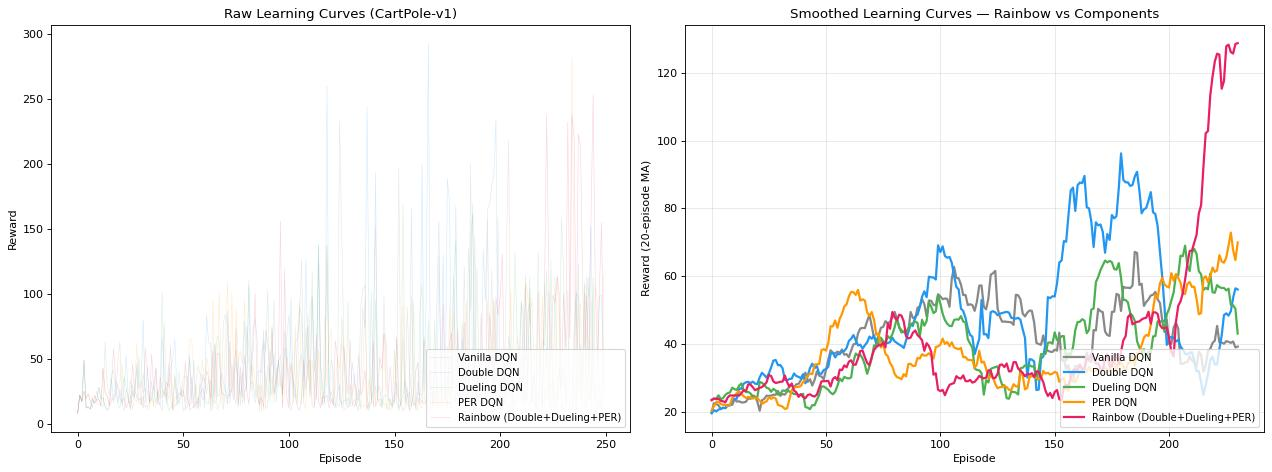

Comparison plot saved.


In [15]:
def smooth(data, window=20):
    """Simple moving average smoothing."""
    if len(data) < window:
        return data
    return np.convolve(data, np.ones(window)/window, mode='valid')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Raw learning curves
ax1 = axes[0]
colors = {
    'vanilla': '#888888',
    'double': '#2196F3',
    'dueling': '#4CAF50',
    'per': '#FF9800',
    'rainbow': '#E91E63'
}
labels = {
    'vanilla': 'Vanilla DQN',
    'double': 'Double DQN',
    'dueling': 'Dueling DQN',
    'per': 'PER DQN',
    'rainbow': 'Rainbow (Double+Dueling+PER)'
}

for agent in agents:
    rewards = all_rewards[agent]
    ax1.plot(rewards, color=colors[agent], alpha=0.2, linewidth=0.5)

ax1.set_xlabel('Episode')
ax1.set_ylabel('Reward')
ax1.set_title('Raw Learning Curves (CartPole-v1)')
ax1.legend([labels[a] for a in agents], loc='lower right', fontsize=9)

# Plot 2: Smoothed learning curves
ax2 = axes[1]
for agent in agents:
    rewards = all_rewards[agent]
    smoothed = smooth(rewards, window=20)
    ax2.plot(smoothed, color=colors[agent], linewidth=2, label=labels[agent])

ax2.set_xlabel('Episode')
ax2.set_ylabel('Reward (20-episode MA)')
ax2.set_title('Smoothed Learning Curves — Rainbow vs Components')
ax2.legend(loc='lower right', fontsize=9)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('rainbow_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Comparison plot saved.")

## 11. Summary Statistics

In [16]:
# Summary table
print(f"{'Agent':<30} {'Mean(50)':<12} {'Std(50)':<12} {'Best':<8} {'Last':<8}")
print("-" * 70)
for agent in agents:
    rewards = all_rewards[agent]
    last_50 = rewards[-50:]
    print(f"{labels[agent]:<30} {np.mean(last_50):<12.1f} {np.std(last_50):<12.1f} "
          f"{max(rewards):<8.0f} {rewards[-1]:<8.0f}")

print()
best_agent = max(agents, key=lambda a: np.mean(all_rewards[a][-50:]))
print(f"Highest final 50-episode average: {labels[best_agent]}")
for agent in agents[1:]:
    diff = np.mean(all_rewards[agent][-50:]) - np.mean(all_rewards['vanilla'][-50:])
    print(f"{labels[agent]:<30} vs Vanilla DQN: {diff:+.1f}")

Agent                          Mean(50)     Std(50)      Best     Last    
----------------------------------------------------------------------
Vanilla DQN                    39.4         42.3         233      16      
Double DQN                     44.1         34.1         293      21      
Dueling DQN                    51.7         45.2         170      13      
PER DQN                        60.0         48.3         282      115     
Rainbow (Double+Dueling+PER)   87.2         70.3         253      33      

Highest final 50-episode average: Rainbow (Double+Dueling+PER)
Double DQN                     vs Vanilla DQN: +4.7
Dueling DQN                    vs Vanilla DQN: +12.2
PER DQN                        vs Vanilla DQN: +20.6
Rainbow (Double+Dueling+PER)   vs Vanilla DQN: +47.8


## 12. Optional Extension: Multi-step Returns

The full Rainbow uses **n-step returns** for faster credit assignment. Instead of bootstrapping from 1 step:

`y = r + γ * Q(s', a*)`

n-step accumulates n rewards before bootstrapping:

`y = Σ_{k=0}^{n-1} γ^k * r_{t+k+1} + γ^n * Q(s_{t+n}, a*)`

This propagates rewards faster through the Q-function. Below is a standalone demonstration comparing 1-step vs 3-step Double DQN.

In [17]:
class NStepReplayBuffer:
    """Replay buffer with n-step return computation."""
    def __init__(self, capacity, n_step=3, gamma=0.99):
        self.capacity = capacity
        self.n_step = n_step
        self.gamma = gamma
        self.buffer = deque(maxlen=capacity)
        self.n_step_buffer = deque(maxlen=n_step)

    def _get_n_step_info(self):
        """Compute n-step return and the n-step-later state."""
        reward, next_state, done = 0.0, None, False
        for i, (s, a, r, ns, d) in enumerate(self.n_step_buffer):
            reward += (self.gamma ** i) * r
            next_state = ns
            done = d
            if d:
                break
        # The initial state and action from the first transition in the buffer
        first_state, first_action = self.n_step_buffer[0][0], self.n_step_buffer[0][1]
        return first_state, first_action, reward, next_state, done

    def push(self, state, action, reward, next_state, done):
        self.n_step_buffer.append((state, action, reward, next_state, done))
        if len(self.n_step_buffer) == self.n_step or done:
            s, a, r, ns, d = self._get_n_step_info()
            self.buffer.append((s, a, r, ns, float(d)))
            if done:
                self.n_step_buffer.clear()

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (
            torch.FloatTensor(np.array(states)).to(device),
            torch.LongTensor(actions).to(device),
            torch.FloatTensor(rewards).to(device),
            torch.FloatTensor(np.array(next_states)).to(device),
            torch.FloatTensor(dones).to(device)
        )

    def __len__(self):
        return len(self.buffer)


def train_nstep_double_dqn(num_episodes=NUM_EPISODES, n_step=N_STEP, seed=SEED):
    """Train Double DQN with n-step returns."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    env = gym.make(ENV_NAME)
    policy_net = QNetwork(STATE_DIM, ACTION_DIM, HIDDEN_DIM).to(device)
    target_net = QNetwork(STATE_DIM, ACTION_DIM, HIDDEN_DIM).to(device)
    target_net.load_state_dict(policy_net.state_dict())
    target_net.eval()
    optimizer = optim.Adam(policy_net.parameters(), lr=LR)
    buffer = NStepReplayBuffer(BUFFER_SIZE, n_step=n_step, gamma=GAMMA)

    rewards_history = []
    epsilon = EPSILON_START
    step_count = 0

    for episode in range(num_episodes):
        obs, _ = env.reset(seed=seed + episode)
        episode_reward = 0

        for t in range(MAX_STEPS):
            action = select_action(obs, policy_net, epsilon, ACTION_DIM)
            next_obs, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            buffer.push(obs, action, reward, next_obs, float(terminated))
            obs = next_obs
            episode_reward += reward
            step_count += 1

            if len(buffer) >= BATCH_SIZE:
                states, actions, rewards_n, next_states, dones = buffer.sample(BATCH_SIZE)
                q_values = policy_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)
                with torch.no_grad():
                    next_actions = policy_net(next_states).argmax(dim=1)
                    next_q = target_net(next_states).gather(1, next_actions.unsqueeze(1)).squeeze(1)
                    # n-step discounted target
                    target = rewards_n + (GAMMA ** n_step) * next_q * (1 - dones)
                loss = F.smooth_l1_loss(q_values, target)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            if step_count % TARGET_UPDATE_FREQ == 0:
                target_net.load_state_dict(policy_net.state_dict())

            if done:
                break

        epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)
        rewards_history.append(episode_reward)

        if (episode + 1) % 50 == 0:
            avg = np.mean(rewards_history[-50:])
            print(f"  [nstep-{n_step}] Episode {episode+1}/{num_episodes}, Avg(50): {avg:.1f}")

    env.close()
    return rewards_history


# Train n-step Double DQN
print(f"Training {N_STEP}-step Double DQN...")
nstep_rewards = train_nstep_double_dqn(num_episodes=NUM_EPISODES, n_step=N_STEP, seed=SEED)
all_rewards[f'{N_STEP}-step Double'] = nstep_rewards
print(f"  Final 50-episode average: {np.mean(nstep_rewards[-50:]):.1f}")

Training 3-step Double DQN...


  [nstep-3] Episode 50/250, Avg(50): 30.5


  [nstep-3] Episode 100/250, Avg(50): 61.7


  [nstep-3] Episode 150/250, Avg(50): 80.9


  [nstep-3] Episode 200/250, Avg(50): 56.4


  [nstep-3] Episode 250/250, Avg(50): 71.1
  Final 50-episode average: 71.1


## 13. Final Comparison (Including Multi-step)

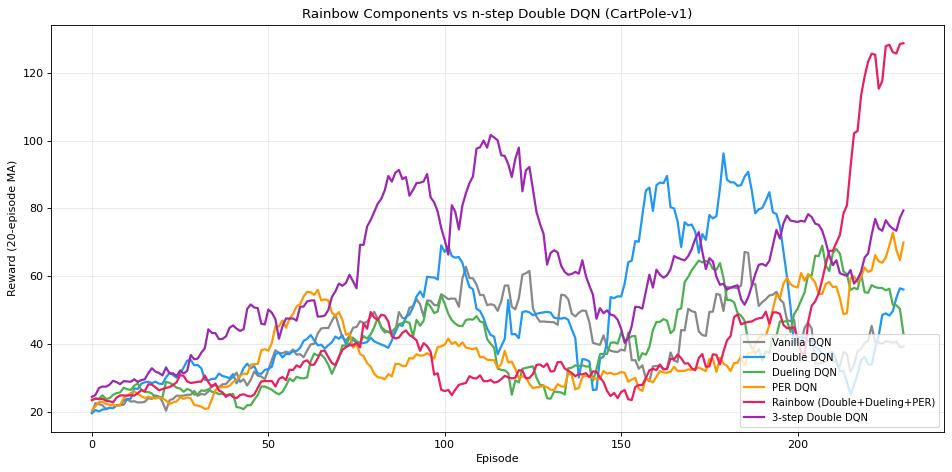


Agent                               Mean(50)     Best    
-------------------------------------------------------
Vanilla DQN                         39.4         233     
Double DQN                          44.1         293     
Dueling DQN                         51.7         170     
PER DQN                             60.0         282     
Rainbow (Double+Dueling+PER)        87.2         253     
3-step Double DQN                   71.1         338     

Total agents compared: 6
Episodes per agent: 250

Rainbow combines: Double DQN + Dueling Networks + Prioritized Experience Replay
Full paper also includes: Multi-step returns + Distributional RL + Noisy Nets


In [18]:
# Final comparison plot including n-step
fig, ax = plt.subplots(figsize=(12, 6))

all_agents = agents + [f'{N_STEP}-step Double']
all_colors = list(colors.values()) + ['#9C27B0']
all_labels_list = list(labels.values()) + [f'{N_STEP}-step Double DQN']

for agent, color, label in zip(all_agents, all_colors, all_labels_list):
    rewards = all_rewards[agent]
    smoothed = smooth(rewards, window=20)
    ax.plot(smoothed, color=color, linewidth=2, label=label)

ax.set_xlabel('Episode')
ax.set_ylabel('Reward (20-episode MA)')
ax.set_title('Rainbow Components vs n-step Double DQN (CartPole-v1)')
ax.legend(loc='lower right', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('rainbow_full_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Final summary
print(f"\n{'Agent':<35} {'Mean(50)':<12} {'Best':<8}")
print("-" * 55)
for agent, label in zip(all_agents, all_labels_list):
    rewards = all_rewards[agent]
    print(f"{label:<35} {np.mean(rewards[-50:]):<12.1f} {max(rewards):<8.0f}")

print(f"\nTotal agents compared: {len(all_agents)}")
print(f"Episodes per agent: {NUM_EPISODES}")
print(f"\nRainbow combines: Double DQN + Dueling Networks + Prioritized Experience Replay")
print(f"Full paper also includes: Multi-step returns + Distributional RL + Noisy Nets")

## 14. Summary

### What the run above shows

All agents ran on CartPole-v1 for 250 episodes with seed 42 and the same settings. Final 50-episode average reward (best single episode in brackets):

| Agent | Final 50-episode average | Best episode |
|---|---|---|
| Vanilla DQN | 39.4 | 233 |
| Double DQN | 44.1 | 293 |
| Dueling DQN (Double target) | 51.7 | 170 |
| PER DQN (Double target) | 60.0 | 282 |
| Rainbow, simplified (Double + Dueling + PER) | 87.2 | 253 |
| 3-step Double DQN | 71.1 | 338 |

- **The combination finished highest, but late.** The simplified Rainbow agent had the highest final 50-episode average, 87.2 against 39.4 for vanilla DQN. The smoothed curves show it below most other agents between episodes 100 and 200; its 20-episode average only climbs to about 125 in the last 30 or so episodes. Its spread over the last 50 episodes is also the largest (standard deviation 70.3), and its last episode scored 33.
- **Each extension alone ended above vanilla DQN** in this run: +4.7 for Double DQN, +12.2 for Dueling and +20.6 for PER.
- **3-step returns helped Double DQN.** The 3-step Double DQN finished at 71.1 against 44.1 for 1-step Double DQN, and led all agents for much of the middle of training.
- **No agent solved CartPole.** No episode reached the 500-step limit; ε is still 0.29 at the end, so many actions are random.

This is one seed on a small task, and the curves are noisy, so these gaps say little about which extension is best. The paper's evidence comes from 57 Atari games and 200M frames per run, where all six components together reached a median human-normalized score of 223% (no-ops). An earlier version of this notebook gave the PER agent the dueling network too, so "PER DQN" and "Rainbow" were the same agent and printed identical numbers; PER DQN now uses the standard network.
